# M09 概覽 | ONNX Runtime：QDQ ONNX 與建 session 時的改寫

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m09_onnx_runtime/00_overview.ipynb)

M08 走 [M07 概覽](../m07_representation_lowering/00_overview.ipynb)的路線 A：ExecuTorch 在**匯出 `.pte` 時**就把 int8 kernel 定下來。這一章走路線 B：Q/DQ 圖匯出成 `.onnx`，交給 ONNX Runtime（ORT）。檔案裡只有標準的 Q/DQ op，換成 int8 kernel 這件事，要等 ORT **建 session 時**才發生。

ORT、Execution Provider（EP）、MLAS 各在哪一層，M07 概覽的前半講過。這一章回答三個問題：

| 問題 | 一句話的答案 | notebook |
|---|---|---|
| Q/DQ 圖匯出成 ONNX 會變成什麼？ | 結構不變，每個 op 換成 ONNX 的標準 op（QDQ format） | M09-1 |
| ORT 在哪一步換上 int8 kernel？ | 建 session 時，`ORT_ENABLE_EXTENDED` 起的 QDQ node fusion | M09-2 |
| ORT 自己的量化工具和 PT2E 差在哪？ | 做同一件事，但把更多決定寫進檔案 | M09-3 |

`onnx`、`onnxscript`、`onnxruntime` 是本專案的主依賴，不需要另外安裝。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m09_onnx_runtime")

In [1]:
#| echo: false
import tempfile
from pathlib import Path

import numpy as np
import onnx
import onnxruntime as ort
import torch
from torch.export import Dim

from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.data import calibration_batches
from common.models import example_inputs, get_model
from common.viz import draw_onnx

quiet()
_ = torch.manual_seed(0)

## 先看一個例子：conv + relu 走完整條路

最小的 conv + relu，從 PyTorch 模型走到 ORT 執行。下面只用 PyTorch、torchao、ONNX Runtime 的原始 API，分三步。

**第 1 步：PT2E，得到 Q/DQ 圖。** 和 M05-1 相同：`export_module` 開動態 batch，quantizer 是 torchao 測試版 XNNPACKQuantizer（M08-1）。

In [2]:
model = get_model("conv_relu").eval()
x = example_inputs()                                            # batch 2

prepared = prepare_pt2e(export_module(model, x), get_xnnpack_quantizer(is_per_channel=True)[0])
with torch.no_grad():
    for batch in calibration_batches(64):
        prepared(*batch)
qdq = convert_pt2e(prepared)                                    # Q/DQ 圖

**第 2 步：匯出成 QDQ ONNX。** `torch.onnx.export` 會拿 `x` 重新 `torch.export` 一次，所以動態 batch 要用 `dynamic_shapes` 再講一次（M09-1 C）：

In [3]:
program = torch.onnx.export(qdq, x, dynamo=True, verbose=False, dynamic_shapes=({0: Dim("batch")},))
assert program is not None
onnx_model = program.model_proto                                # 存檔就是 .onnx

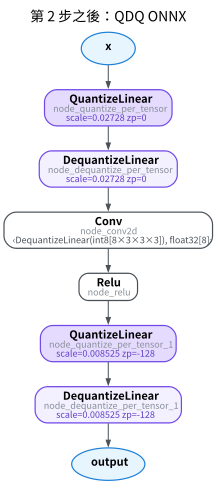

In [4]:
#| echo: false
draw_onnx(onnx_model, title="第 2 步之後：QDQ ONNX")

和 Q/DQ 圖一模一樣，只是換了名字：`quantize_per_tensor` → `QuantizeLinear`、`conv2d` → `Conv`。`Conv` 仍是 fp32 的 op，這個檔案本身沒有任何 int8 kernel。

**第 3 步：ORT 建 session、執行。** `SessionOptions.graph_optimization_level` 選最佳化等級；另外給 `optimized_model_filepath`，ORT 會把改寫後的圖存檔，讓我們看看它做了什麼：

In [5]:
so = ort.SessionOptions()
so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_EXTENDED
with tempfile.TemporaryDirectory() as d:
    so.optimized_model_filepath = str(Path(d) / "optimized.onnx")
    session = ort.InferenceSession(onnx_model.SerializeToString(), so, providers=["CPUExecutionProvider"])
    rewritten = onnx.load(so.optimized_model_filepath)
y = np.asarray(session.run(None, {session.get_inputs()[0].name: torch.randn(5, 3, 16, 16).numpy()})[0])
print("batch 5 的輸出 shape：", y.shape)

batch 5 的輸出 shape： (5, 8, 16, 16)


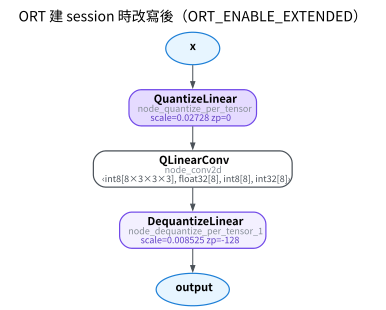

In [6]:
#| echo: false
draw_onnx(rewritten, title="ORT 建 session 時改寫後（ORT_ENABLE_EXTENDED）")

「DequantizeLinear → Conv → Relu → QuantizeLinear」被換成一顆 `QLinearConv`：輸入輸出都是 int8，用 CPU EP 的 int8 kernel 算。檔案沒變，換掉它的是 ORT。

後面的 notebook 用本專案的幾個包裝（`common/onnx_utils.py`，都不是 torch 或 ORT 的 API）：

| 包裝 | 做的事 |
|---|---|
| `xnnpack_qdq(model, x)` | 第 1 步 |
| `to_onnx(gm, x)` | 第 2 步，預設帶 `dynamic_shapes` |
| `ort_session(onnx_model, level)` | 第 3 步的建 session，固定用 CPU EP |
| `optimized_model(onnx_model, level)` | 第 3 步的存檔再讀回，得到改寫後的圖 |
| `ort_quantize(fp32_onnx, ...)` | ORT 自己的量化工具 `quantize_static`（M09-3） |

## 五個圖最佳化等級

這一節整理 ORT v1.30.0 的原始碼，讓結論不受 TinyConvNet 這個模型的限制。官方文件的 Graph Optimizations 頁只寫四個等級，也沒提 QDQ node fusion，已經落後原始碼；以下以原始碼為準，在 macOS arm64、ORT 1.30.0 上實測的部分標出對應的 notebook。

`GraphOptimizationLevel` 有五個值，`abi_session_options.cc` 把它們對應到 ORT 內部的 `TransformerLevel`：

| API 的等級 | 數值 | 內部 Level |
|---|---|---|
| `ORT_DISABLE_ALL` | 0 | `Default` |
| `ORT_ENABLE_BASIC` | 1 | `Level1` |
| `ORT_ENABLE_EXTENDED` | 2 | `Level2` |
| `ORT_ENABLE_LAYOUT` | 3 | `Level3` |
| `ORT_ENABLE_ALL` | 99 | `MaxLevel`（= `Level4`） |

每一級都包含前一級的所有改寫。`InferenceSession` 不指定時用 `ORT_ENABLE_ALL`。

In [7]:
print({name: int(level) for name, level in ort.GraphOptimizationLevel.__members__.items()})

{'ORT_DISABLE_ALL': 0, 'ORT_ENABLE_BASIC': 1, 'ORT_ENABLE_EXTENDED': 2, 'ORT_ENABLE_LAYOUT': 3, 'ORT_ENABLE_ALL': 99}


### 建 session 時的順序

```text
讀入 .onnx
  → 必要的步驟           不論等級都跑
  → Level1（BASIC）      在分配 EP 之前：與 EP 無關
  → 分配 EP              每個 node 交給一個 EP
  → Level2～Level4       在分配 EP 之後：多半只對特定 EP 做
  → 插 Cast、Memcpy      必要的步驟
```

Level1 在分配 EP 之前跑，所以對所有 EP 都有效；Level2 起的改寫，原始碼裡大多列了適用的 EP 清單（`inference_session.cc`、`graph_transformer_utils.cc`）。

### 每一級新加的內容

| 等級 | 新加的 | 實測 |
|---|---|---|
| `ORT_DISABLE_ALL` | 必要的步驟：展開 ONNX function、`EnsureUniqueDQForNodeUnit`（一個 DQ 給多個 op 用時複製開）、插 Cast／Memcpy | M09-2：多一個 `/duplicated` 的 DQ |
| `ORT_ENABLE_BASIC` | 與 EP 無關的化簡：去掉多餘 node、常數摺疊、Conv+BN／Add／Mul 融合；QDQ 前處理：`WeightBiasQuantization`（bias 量化成 int32） | M09-2：int32 bias = round(b / (s_x·s_w)) |
| `ORT_ENABLE_EXTENDED` | QDQ node fusion；`ReluQuantFusion`、`ClipQuantFusion`；fp32 的融合（Conv+激活 → `FusedConv`、Transformer 類的 Attention、LayerNorm 等） | M09-2：`QLinearConv`、Relu 消失 |
| `ORT_ENABLE_LAYOUT` | CPU 的 layout：`NhwcTransformer`（int8 `QLinearConv`、fp16 Conv 等換成 NHWC）；`NchwcTransformer`（fp32 Conv，只在 x86-64） | M09-2：`QLinearConv` 換成 NHWC |
| `ORT_ENABLE_ALL` | `FuseFp16InitializerToFp32NodeTransformer`：fp16 常數轉 fp32 | M09-2：和 LAYOUT 相同 |

三個細節：

- BASIC 的常數摺疊在 QDQ 模型上**跳過 DQ**，保住「DQ → op → Q」單元，留給 Level2 融合（原始碼註解）。
- `ReluQuantFusion` 只在 Relu 後面的 QuantizeLinear 的 zero point 等於該型別的下限（int8 是 -128、uint8 是 0）時做，只對 CPU EP。這時 Q 的 clamp 已經做了 Relu 的事（M09-2）。
- LAYOUT 換 NHWC，是因為 CPU EP 的 int8 conv kernel 只在 NHWC 上計算：NCHW 的 `QLinearConv` 每次執行，都在 kernel 內部把每張圖轉成 NHWC、算完再轉回 NCHW（`qlinearconv.cc`）。`NhwcTransformer` 把轉置提到圖上，相鄰而互相抵消的 Transpose 再被消掉，整段 int8 區段只在頭尾各轉置一次（M09-2）。

### QDQ node fusion 的三組

`qdq_selector_action_transformer.cc` 依 op 分組（M09-2 的 TinyConvNet 實測了 Conv、Add、Gemm、MaxPool、Reshape、ReduceMean，其餘的 op 只讀原始碼）：

| 分組 | 例子 | 結果 |
|---|---|---|
| 換成 int8 op | Conv、MatMul、Gemm、Add、Mul、Concat、Sigmoid、Softmax | `QLinear*`／`com.microsoft.QGemm` |
| 拿掉 Q/DQ | MaxPool、Reshape、Transpose、Flatten | 原 op 直接在 int8 上做 |
| 不在清單上 | ReduceMean | 留在 fp32，前後各一次 int8 ↔ fp32 |

`com.microsoft.*` 是 ORT 自己定義的 op，不在 ONNX 標準裡。

### 與平台有關

同一個 `.onnx`，在 x86 上改寫出來的圖和 arm 不同（讀原始碼；這兩點都沒有在 x86 上實測）：

- **int8 或 uint8**：`QDQIsInt8Allowed()` 的預設值在 arm 是允許、在其他平台是不允許。不允許時，Level2 先跑 `QDQS8ToU8Transformer`，把 int8 activation 改成 uint8。
- **NCHWc**：`NchwcTransformer` 的條件是 `MlasNchwcGetBlockSize() > 1`，只有 x86-64 成立。

ORT 存最佳化後的圖時，等級高於 EXTENDED 會印警告：圖可能含硬體相關的最佳化，只能在同樣的環境用。所以要比較改寫結果，就在目標機器上建 session 看。

## 和 M08 的對照

| | M08（ExecuTorch） | M09（ONNX Runtime） |
|---|---|---|
| 部署檔 | `.pte` | `.onnx` |
| 何時決定 kernel | 匯出時（partitioner） | 建 session 時（EP + 最佳化等級） |
| 誰認出 `dq → op → q` | XNNPACK delegate | ORT 的 QDQ node fusion（EXTENDED 起） |
| fp32 bias | lowering 時量化成 int32 | 建 session 時量化成 int32（BASIC） |
| CPU 的 int8 kernel | XNNPACK | MLAS（CPU EP） |
| 動態 batch | 這門課用 static shape | 匯出時給 `dynamic_shapes` 就能跑任意 batch |

兩者的輸出都和 Q/DQ 圖不保證逐位元相同，原因同 M08 概覽〈和 Q/DQ 圖的數值差異〉；比較時照 M07 概覽〈比較後端之前的規矩〉。

## CPU 與 VPU／NPU 的差別（接 M10）

這一章的 CPU EP 很寬鬆：per-channel、非對稱 activation、動態 batch 都吃，沒有 int8 版本的 op 就留在 fp32。VPU／NPU 類的硬體通常窄得多（一般說法，本專案沒有實機驗證）：

| 限制 | CPU EP（本章） | 常見的 VPU／NPU |
|---|---|---|
| activation 的量化 | per-tensor affine | 常要求 per-tensor 對稱 |
| scale | 任意 fp32 | 有時要求 2 的冪次（用 shift 實作） |
| 支援的 op | 寬；不支援的留在 fp32 | 窄；不支援的要切回 CPU |
| shape | 動態 batch 可以 | 多半要 static shape |

M10 用 PT2E 的 Quantizer API 把這些限制寫成一個自訂後端，再檢查 Q/DQ 圖是否合規、把清單外的 op 切回 CPU。

## 小結與本章地圖

- QDQ ONNX 是後端中立的：檔案裡只有標準的 Q/DQ op，要不要換成 int8 kernel，由執行時的 EP 與最佳化等級決定。
- 五個等級各有分工：DISABLE_ALL 只做必要的準備，BASIC 做與 EP 無關的化簡與 bias 量化，EXTENDED 做 QDQ node fusion，LAYOUT 換 layout，ALL 只多 fp16 的處理。
- 哪些 op 能變成 int8 有固定清單；layout 這一級和 CPU 架構有關。

| notebook | 回答的問題 |
|---|---|
| [M09-1 匯出 QDQ ONNX](01_onnx_qdq_export.ipynb) | PT2E 的 op 各變成哪個 ONNX op；檔案裡存了什麼；動態 batch |
| [M09-2 ORT 的五個等級](02_ort_qdq_fusion.ipynb) | TinyConvNet 在每一級被改成什麼；int32 bias；Relu 為什麼消失 |
| [M09-3 ORT 的量化工具](03_ort_quant_compare.ipynb) | `quantize_static` vs PT2E；QDQ format 與 QOperator format |

這一章刻意跳過的：CPU 以外的 EP（XNNPACK EP 不在 pip 版的 ORT 裡；Core ML 等 EP 的切法沒有查）；ORT 輸出與 Q/DQ 圖的逐位元比較與 latency。

## 參考資料

- ONNX Runtime 文件：[Graph Optimizations](https://onnxruntime.ai/docs/performance/model-optimizations/graph-optimizations.html)、[Quantize ONNX models](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html)、[Execution Providers](https://onnxruntime.ai/docs/execution-providers/)
- ORT v1.30.0 原始碼（[GitHub](https://github.com/microsoft/onnxruntime/tree/v1.30.0)）：
  - `include/onnxruntime/core/session/onnxruntime_c_api.h`：`GraphOptimizationLevel` 的定義
  - `onnxruntime/core/session/abi_session_options.cc`：等級 → `TransformerLevel`
  - `onnxruntime/core/session/inference_session.cc`：建 session 的順序、必要的步驟
  - `onnxruntime/core/optimizer/graph_transformer_utils.cc`：每個 Level 登記的 transformer
  - `onnxruntime/core/optimizer/qdq_transformer/selectors_actions/qdq_selector_action_transformer.cc`：QDQ fusion 清單
  - `onnxruntime/core/optimizer/qdq_transformer/relu_quantizelinear.cc`：`ReluQuantFusion`
  - `onnxruntime/core/optimizer/nhwc_transformer.cc`：NHWC 的 op 清單
  - `onnxruntime/core/providers/cpu/quantization/qlinearconv.cc`：int8 conv kernel，NCHW 時在內部轉置
- PyTorch 文件：[torch.onnx](https://docs.pytorch.org/docs/stable/onnx.html)